<a href="https://colab.research.google.com/github/Renyambar/Reny_MachineLearning/blob/main/JS10/JS10_04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Langkah 1 - Import Library

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

##Langkah 2 - Load Dataset

In [26]:
import zipfile
import os

def unzip_file(zip_src, dest_dir):
    if not os.path.exists(zip_src):
        print(f"Error: File '{zip_src}' tidak ditemukan. Harap pastikan file sudah diunggah.")
        return False

    print(f"Mengekstrak '{zip_src}' ke '{dest_dir}'...")
    try:
        with zipfile.ZipFile(zip_src, 'r') as zip_ref:
            zip_ref.extractall(dest_dir)
        print("Ekstraksi sukses!")
        return True
    except zipfile.BadZipFile:
        print("Error: File rusak atau bukan merupakan format ZIP yang valid (BadZipFile).")
        return False
    except Exception as e:
        print(f"Terjadi kesalahan saat mengekstrak: {e}")
        return False

# Menjalankan fungsi ekstraksi
unzip_file('/content/images.zip', '/content/')

Mengekstrak '/content/images.zip' ke '/content/'...
Ekstraksi sukses!


True

In [27]:
import os

def check_directory_structure(base_dir):
    if not os.path.exists(base_dir):
        print(f"Error: Direktori '{base_dir}' tidak ditemukan!")
        return

    print(f"Isi dari direktori '{base_dir}':")
    for root, dirs, files in os.walk(base_dir):
        # Menghitung level kedalaman direktori untuk format cetak yang rapi
        level = root.replace(base_dir, '').count(os.sep)
        indent = ' ' * 4 * level
        print(f"{indent}[D] {os.path.basename(root)}/")

        # Tampilkan beberapa sampel file gambar jika ada
        sub_indent = ' ' * 4 * (level + 1)
        jpg_files = [f for f in files if f.endswith('.jpg')]
        if jpg_files:
            print(f"{sub_indent}Jumlah gambar (.jpg): {len(jpg_files)}")
            print(f"{sub_indent}Sampel file: {jpg_files[:5]}")

# Mengecek struktur direktori images
check_directory_structure('images')

Isi dari direktori 'images':
[D] images/
    [D] test/
        [D] day/
            Jumlah gambar (.jpg): 80
            Sampel file: ['20151102_102556.jpg', '20151102_225053.jpg', '20151102_105546.jpg', '20151102_123122.jpg', '20151102_215100.jpg']
        [D] night/
            Jumlah gambar (.jpg): 80
            Sampel file: ['20151102_043537.jpg', '20151102_031422.jpg', '20151101_072507.jpg', '20151102_044410.jpg', '20151102_042327.jpg']
    [D] training/
        [D] day/
            Jumlah gambar (.jpg): 120
            Sampel file: ['20151103_161128.jpg', '20151101_202504.jpg', '20151103_094527.jpg', '20151101_191801.jpg', '20151101_212503.jpg']
        [D] night/
            Jumlah gambar (.jpg): 120
            Sampel file: ['20151102_210132.jpg', '20151102_020536.jpg', '20151102_011408.jpg', '20151102_084936.jpg', '20151102_030529.jpg']


In [28]:
# Load images and labels from a directory structure
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in p.glob('*'):
        label = folder.name
        for file in folder.glob('*.jpg'):
            img = cv2.imread(str(file))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))
    return img_list

train_dir = "images/training/"
test_dir  = "images/test/"

train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

In [29]:
# Load images and labels from a directory structure
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in p.glob('*'):
        label = folder.name
        for file in folder.glob('*.jpg'):
            img = cv2.imread(str(file))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))
    return img_list

train_dir = "images/training/"
test_dir  = "images/test/"

train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

##Langkah 2 - Pra Pengolahan

In [30]:
# Preprocess images: resize and encode labels
def resize_image(img, size=(256,256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []
    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)

##Langkah 3 - Ekstraksi Fitur

In [31]:
# Extract HOG features
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(gray,
                        orientations=9,
                        pixels_per_cell=(8,8),
                        cells_per_block=(2,2),
                        block_norm='L2-Hys',
                        visualize=False,
                        feature_vector=True)
        feats.append(hog_feat)
    return np.array(feats)

X_train_feat = extract_hog(X_train_img)
X_test_feat  = extract_hog(X_test_img)

##Langkah 4 - Standardisasi Fitur

In [32]:
# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

##Langkah 5 - Buat Data Latih dan Validasi

In [33]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

# Convert label ke numpy array
y_train = np.array(y_train)
y_val   = np.array(y_val)
y_test  = np.array(y_test)

##Langkah 6 - Buat Model ANN

In [34]:
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

##Langkah 7 - Latih Model

In [35]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 145ms/step - accuracy: 0.8333 - loss: 1.0510 - val_accuracy: 0.9583 - val_loss: 0.1915
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.9688 - loss: 0.1813 - val_accuracy: 1.0000 - val_loss: 0.0154
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.9948 - loss: 0.0174 - val_accuracy: 0.9583 - val_loss: 0.2587
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.9948 - loss: 0.0042 - val_accuracy: 1.0000 - val_loss: 6.8904e-05
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 1.0000 - loss: 9.8418e-06 - val_accuracy: 1.0000 - val_loss: 3.4199e-04
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 1.0000 - loss: 7.7466e-06 - val_accuracy: 1.0000 - val_loss: 0.0019
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 1.0000 - loss: 2.3399e-05 - val_accuracy: 1.0000 - val_loss: 0.0067
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 1.0000 - loss: 3.7357e-05 - val_accuracy: 1

##Langkah 8 - Evaluasi Model dengan Data Test

In [36]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
print("Akurasi Test:", test_acc)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8438 - loss: 1.2441
Akurasi Test: 0.84375


##Langkah 9 - Buat Laporan Performansi Model

In [37]:
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
              precision    recall  f1-score   support

           0       0.92      0.75      0.83        80
           1       0.79      0.94      0.86        80

    accuracy                           0.84       160
   macro avg       0.86      0.84      0.84       160
weighted avg       0.86      0.84      0.84       160

[[60 20]
 [ 5 75]]


##Langkah 10 - Visualisasi Proses Training

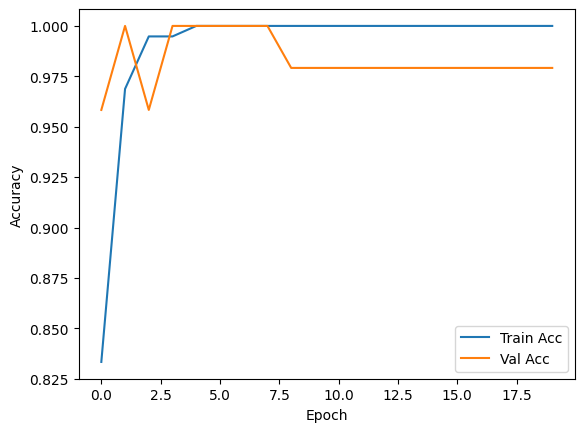

In [38]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

##Langkah 11 - Simpan Model

In [39]:
model.save('day_night_classifier_model.h5')